# Chapter 3 — Where Did the Votes Come From? (The Core Innovation)

## The story so far

Lula gained about 10.4 million votes between round 1 and round 2; Flávio gained about 3.7 million. Together, the two finalists gained about 14.1 million votes in round 2 compared with round 1. But the total number of *valid* votes only rose by about 4.8 million. So where did the other ~9.3 million come from?

Answer, in one line: **from the voters whose candidates were eliminated in round 1.** Their votes were already counted in round 1 — for someone else. In round 2 they counted for Lula or Flávio instead. That is not new votes appearing from nowhere; it is the same voters, choosing again, exactly as Chapter 1's toy showed.

> **Read this before the numbers — the uncertainty warning, in plain words.**
> This chapter estimates flows from **aggregate data**: totals per municipality, not individual voters. The TSE does not publish, and nobody in this project tracks, how any individual person voted. So when we say "votes from eliminated candidates", we mean: *the total pool of eliminated-candidate votes was this big, and the gains fit inside it in this way*. We can prove what was **arithmetically possible** and what was **impossible**, and we can show **bounds** (the smallest and largest amounts that must/may have come from each source). We cannot prove that a particular voter switched, stayed home, or showed up for the first time. Any analysis that claims to know individual voters' choices from these totals is over-claiming — this one does not.

## The accounting identity (the whole trick, in one equation)

Think of round 2's votes for the two finalists as coming from four buckets. Everything must add up, and it does — to within a tiny residual explained below:

```
(Lula's gain + Flavio's gain)  =  (eliminated candidates' round-1 votes)
                                + (increase in valid votes between rounds)
```

The increase in valid votes itself breaks down as:

```
increase in valid votes  =  (more voters turned out) + (fewer blank/null votes)
```

Check it with the real numbers below. If the left side were *bigger* than the right side, something would be arithmetically impossible and worth investigating. It is not — as you will see, the pools are bigger than the gains, with room to spare.

In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib geopandas

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


In [3]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
nat = pd.read_csv(PROC / "national_2026.csv")
r1, r2 = nat[nat["NR_TURNO"] == 1].iloc[0], nat[nat["NR_TURNO"] == 2].iloc[0]
lula_gain = r2["lula"] - r1["lula"]
flavio_gain = r2["flavio"] - r1["flavio"]
combined_gain = lula_gain + flavio_gain
elim_pool = r1["other_valid"]
valid_increase = r2["valid"] - r1["valid"]
turnout_increase = r2["QT_COMPARECIMENTO"] - r1["QT_COMPARECIMENTO"]
blank_null_r1 = r1["QT_VOTOS_BRANCOS"] + r1["QT_VOTOS_NULOS"]
blank_null_r2 = r2["QT_VOTOS_BRANCOS"] + r2["QT_VOTOS_NULOS"]
blank_null_drop = blank_null_r1 - blank_null_r2
residual = combined_gain - elim_pool - valid_increase
print(f"Lula gain:    {lula_gain:,} votes  ({r1['lula']:,} -> {r2['lula']:,})")
print(f"Flavio gain:  {flavio_gain:,} votes  ({r1['flavio']:,} -> {r2['flavio']:,})")
print(f"Combined gain of the two finalists: {combined_gain:,}")
print()
print(f"Eliminated candidates' round-1 votes: {elim_pool:,}")
print(f"Increase in valid votes:             {valid_increase:,}")
print(f"  = turnout increase ({turnout_increase:,}) + blank/null drop ({blank_null_drop:,}) + small residual")
print(f"  (turnout: {r1['QT_COMPARECIMENTO']:,} -> {r2['QT_COMPARECIMENTO']:,}; "
      f"blank/null: {blank_null_r1:,} -> {blank_null_r2:,})")
print(f"Eliminated pool + valid increase = {elim_pool + valid_increase:,}")
print(f"Residual of that identity (combined gain minus those two): {residual:,} — it is exactly")
print("zero, because valid votes are defined as Lula + Flavio + other, so the identity holds")
print("by construction. It is a check that the tables add up, not an independent discovery.")
second_resid = valid_increase - (turnout_increase + blank_null_drop)
print(f"Second reconciliation: turnout increase + blank/null drop = {turnout_increase + blank_null_drop:,},")
print(f"which is {second_resid:,} short of the valid-vote increase ({valid_increase:,}). That 5,246-vote")
print("gap (0.04% of the combined gain) is the only small residual in this chapter; it reflects")
print("small TSE definitional differences (e.g. annulled / sub-judice votes) between the vote")
print("and turnout files, not missing votes.")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
Lula gain:    10,376,694.0 votes  (53,879,538.0 -> 64,256,232.0)
Flavio gain:  3,721,538.0 votes  (56,104,503.0 -> 59,826,041.0)
Combined gain of the two finalists: 14,098,232.0

Eliminated candidates' round-1 votes: 9,316,747.0
Increase in valid votes:             4,781,485.0
  = turnout increase (2,960,239.0) + blank/null drop (1,816,000.0) + small residual
  (turnout: 125,275,835.0 -> 128,236,074.0; blank/null: 5,969,801.0 -> 4,153,801.0)
Eliminated pool + valid increase = 14,098,232.0
Residual of that identity (combined gain minus those two): 0.0 — it is exactly
zero, because valid votes are defined as Lula + Flavio + other, so the identity holds
by construction. It is a check that the tables add up, not an independent discovery.
Second reconciliation: turnout increase + blank/null drop = 4,776,239.0,
which is 5,246.0 short of the valid-vote increase (4,781,485.0). That 5,246-vote
gap (0.04% of the combined gai

## What the pools can and cannot explain — Lula's gain, in bounds

Now the sharper question: **Lula's** gain alone, 10.38 million. Could it have come only from eliminated-candidate voters? No — and that "no" is a real, provable finding:

- The eliminated pool is 9.32 million votes. Lula's gain (10.38 million) is **larger** than the whole pool. Even if Lula had won *every single* eliminated-candidate voter — which he did not, because Flávio also gained 3.72 million — he would still be about 1.06 million short.
- **Therefore, at least ~1.06 million of Lula's gain must have come from somewhere else**: new voters who turned out in round 2, round-1 blank/null voters who chose a candidate in round 2, round-1 Flávio voters who switched to Lula, or a mix of all three. Aggregate data cannot split that remainder between those three sources — anyone who gives you an exact split is guessing.
- The same logic in reverse: Flávio's gain (3.72 million) *could* in principle have come entirely from the eliminated pool, since it is smaller than the pool. Bounds are asymmetric, and the notebook says so rather than forcing symmetry.

### A benchmark, not an estimate: the "proportional split"

Suppose, just as a benchmark, that eliminated voters and new valid voters had split between Lula and Flávio in exactly the same proportions as the round-2 result itself (51.79% Lula / 48.21% Flávio). Then Lula would have gained about 7.3 million from those two pools combined — well short of his actual 10.38 million. In other words, **the voters who had to choose again, and the new voters, leaned toward Lula more strongly than the round-2 average**. That is a statement about pools, not about individuals, but it is a meaningful one: the comeback was not a mechanical replay of round-2 shares; transfer and turnout voters favoured Lula disproportionately. (The benchmark is computed below; it is labelled a benchmark precisely because the true split is unknown.)

In [4]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
nat = pd.read_csv(PROC / "national_2026.csv")
r1, r2 = nat[nat["NR_TURNO"] == 1].iloc[0], nat[nat["NR_TURNO"] == 2].iloc[0]
lula_gain = r2["lula"] - r1["lula"]; elim_pool = r1["other_valid"]
valid_increase = r2["valid"] - r1["valid"]
shortfall = lula_gain - elim_pool
print(f"Lula gain / eliminated pool = {lula_gain/elim_pool*100:.1f}%  (>100%: eliminated votes ALONE cannot explain Lula's gain)")
print(f"Minimum Lula gain that must come from non-eliminated sources: {shortfall:,} votes")
print()
share_r2 = r2["lula_share_valid"]
benchmark = (elim_pool + valid_increase) * share_r2
print(f"Proportional-split benchmark for Lula's gain: ({elim_pool:,} + {valid_increase:,}) x {share_r2*100:.2f}% = {benchmark:,.0f}")
print(f"Actual Lula gain: {lula_gain:,}  — benchmark shortfall: {lula_gain - benchmark:,.0f}")
print("Interpretation (pools, not individuals): transfer/new voters leaned Lula more than the round-2 average.")
# Save the decomposition table (national + by region) for the README and Chapter 5.
mun = pd.read_csv(PROC / "mun_2026.csv")
wide = mun.pivot_table(index=["SG_UF", "region", "CD_MUNICIPIO", "NM_MUNICIPIO"],
                       columns="NR_TURNO", values=["lula", "flavio", "other_valid", "valid",
                       "QT_APTOS", "QT_COMPARECIMENTO", "QT_ABSTENCOES", "QT_VOTOS_BRANCOS", "QT_VOTOS_NULOS"],
                       aggfunc="sum")
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide = wide.reset_index()
rows = []
def add_row(scope, d):
    lg = d["lula_2"].sum() - d["lula_1"].sum()
    fg = d["flavio_2"].sum() - d["flavio_1"].sum()
    rows.append({"scope": scope, "lula_gain": lg, "flavio_gain": fg, "combined_gain": lg + fg,
                 "eliminated_pool_r1": d["other_valid_1"].sum(),
                 "valid_increase": d["valid_2"].sum() - d["valid_1"].sum(),
                 "turnout_increase": d["QT_COMPARECIMENTO_2"].sum() - d["QT_COMPARECIMENTO_1"].sum(),
                 "blank_null_drop": (d["QT_VOTOS_BRANCOS_1"].sum() + d["QT_VOTOS_NULOS_1"].sum())
                                    - (d["QT_VOTOS_BRANCOS_2"].sum() + d["QT_VOTOS_NULOS_2"].sum()),
                 "lula_gain_over_elim_pool_pct": lg / d["other_valid_1"].sum() * 100 if d["other_valid_1"].sum() else None,
                 "min_lula_gain_from_other_sources": max(lg - d["other_valid_1"].sum(), 0)})
add_row("Brazil (incl. abroad)", wide)
for reg, d in wide.groupby("region"):
    add_row(reg, d)
dec = pd.DataFrame(rows)
dec.to_csv(PROC / "decomposition_2026.csv", index=False)
print(); print(dec.to_string(index=False))

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
Lula gain / eliminated pool = 111.4%  (>100%: eliminated votes ALONE cannot explain Lula's gain)
Minimum Lula gain that must come from non-eliminated sources: 1,059,947.0 votes

Proportional-split benchmark for Lula's gain: (9,316,747.0 + 4,781,485.0) x 51.79% = 7,300,795
Actual Lula gain: 10,376,694.0  — benchmark shortfall: 3,075,899
Interpretation (pools, not individuals): transfer/new voters leaned Lula more than the round-2 average.

                scope  lula_gain  flavio_gain  combined_gain  eliminated_pool_r1  valid_increase  turnout_increase  blank_null_drop  lula_gain_over_elim_pool_pct  min_lula_gain_from_other_sources
Brazil (incl. abroad)   10376694      3721538       14098232             9316747         4781485           2960239          1816000                    111.376793                           1059947
               Abroad      42767        27597          70364               29595           40

## The same decomposition, by region

The regional table above is the first place where the story stops being just national. Read it as: *in which regions did Lula's gain exceed the local eliminated pool?* Where it did, that region too needed new voters, blank/null switchers, or Flávio switchers. Where it did not, the eliminated pool alone could arithmetically cover it. The pattern — which regions needed the extra sources most — is part of Chapter 5's breadth test.

## Was the gain broad or concentrated? The municipality evidence

National pools tell us the comeback was arithmetically possible. Municipality data tells us whether it was *broad* — thousands of small gains everywhere — or *concentrated* — a few places doing all the work. Broad is what transfer + turnout normally looks like; concentrated is what you would check first if you suspected something local.

In [5]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
mun = pd.read_csv(PROC / "mun_2026.csv")
dom = mun[mun["SG_UF"] != "ZZ"].copy()
piv = dom.pivot_table(index=["SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO"], columns="NR_TURNO",
                      values=["lula", "flavio", "valid", "QT_APTOS", "QT_COMPARECIMENTO", "QT_ABSTENCOES"],
                      aggfunc="sum")
piv.columns = [f"{a}_{b}" for a, b in piv.columns]; piv = piv.reset_index()
piv["lula_gain"] = piv["lula_2"] - piv["lula_1"]
piv["lula_share_1"] = piv["lula_1"] / piv["valid_1"]; piv["lula_share_2"] = piv["lula_2"] / piv["valid_2"]
piv["swing_pp"] = (piv["lula_share_2"] - piv["lula_share_1"]) * 100
piv["abst_drop_pp"] = (piv["QT_ABSTENCOES_1"] / piv["QT_APTOS_1"] - piv["QT_ABSTENCOES_2"] / piv["QT_APTOS_2"]) * 100
print(f"Municipalities (domestic): {len(piv):,}")
print(f"Lula gained votes in {(piv['lula_gain'] > 0).mean()*100:.1f}% of municipalities "
      f"({(piv['lula_gain'] > 0).sum():,} of {len(piv):,})")
print(f"Lula's vote SHARE rose in {(piv['swing_pp'] > 0).mean()*100:.1f}% of municipalities")
print(f"Median municipality swing to Lula: {piv['swing_pp'].median():.2f} percentage points")
print(f"Median abstention drop (round 1 -> round 2): {piv['abst_drop_pp'].median():.2f} points")
print(f"Correlation (municipalities) between abstention drop and Lula vote gain: "
      f"{piv['abst_drop_pp'].corr(piv['lula_gain']):.3f}")
print(f"Correlation between abstention drop and Lula share swing: {piv['abst_drop_pp'].corr(piv['swing_pp']):.3f}")
tot_gain = piv.loc[piv["lula_gain"] > 0, "lula_gain"].sum()
for k in [10, 100, 1000]:
    top = piv.nlargest(k, "lula_gain")
    print(f"Top {k} municipalities by Lula gain: {top['lula_gain'].sum()/tot_gain*100:.1f}% of all positive Lula gains, "
          f"but {top['QT_APTOS_1'].sum()/piv['QT_APTOS_1'].sum()*100:.1f}% of the electorate")
piv.to_csv(PROC / "mun_swing_2026.csv", index=False)
print("Saved municipality swing table to data/processed/mun_swing_2026.csv")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
Municipalities (domestic): 5,571
Lula gained votes in 98.6% of municipalities (5,491 of 5,571)
Lula's vote SHARE rose in 99.9% of municipalities
Median municipality swing to Lula: 5.13 percentage points
Median abstention drop (round 1 -> round 2): 1.88 points
Correlation (municipalities) between abstention drop and Lula vote gain: 0.052
Correlation between abstention drop and Lula share swing: 0.083
Top 10 municipalities by Lula gain: 21.0% of all positive Lula gains, but 17.3% of the electorate
Top 100 municipalities by Lula gain: 45.2% of all positive Lula gains, but 38.7% of the electorate
Top 1000 municipalities by Lula gain: 79.2% of all positive Lula gains, but 72.4% of the electorate
Saved municipality swing table to data/processed/mun_swing_2026.csv


Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


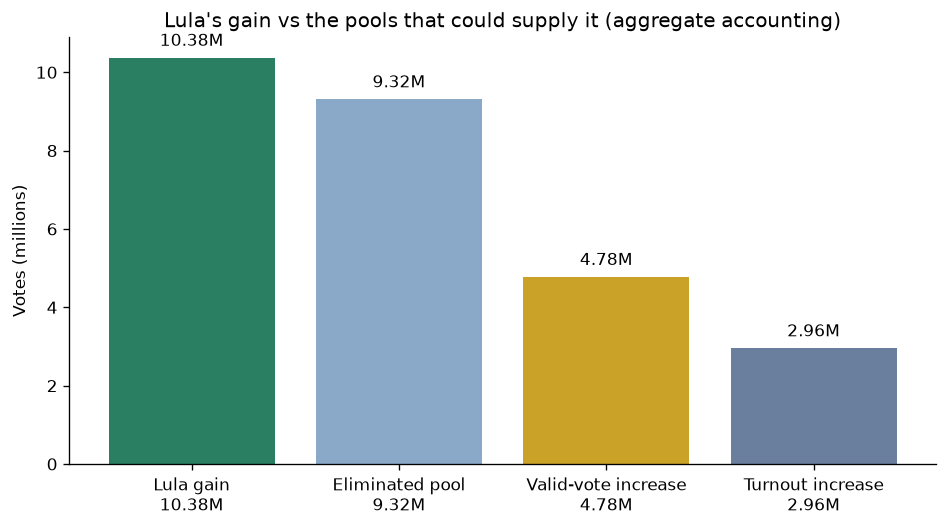

In [6]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
# Chart: the pools vs the gain — is the comeback arithmetically covered?
nat = pd.read_csv(PROC / "national_2026.csv")
r1, r2 = nat[nat["NR_TURNO"] == 1].iloc[0], nat[nat["NR_TURNO"] == 2].iloc[0]
fig, ax = plt.subplots(figsize=(8, 4.5))
cats = ["Lula gain\n10.38M", "Eliminated pool\n9.32M", "Valid-vote increase\n4.78M", "Turnout increase\n2.96M"]
vals = [(r2["lula"] - r1["lula"]) / 1e6, r1["other_valid"] / 1e6,
        (r2["valid"] - r1["valid"]) / 1e6, (r2["QT_COMPARECIMENTO"] - r1["QT_COMPARECIMENTO"]) / 1e6]
ax.bar(cats, vals, color=["#2a7f62", "#8aa8c8", "#c9a227", "#6a7f9e"])
for i, v in enumerate(vals): ax.text(i, v + 0.3, f"{v:.2f}M", ha="center")
ax.set_ylabel("Votes (millions)")
ax.set_title("Lula's gain vs the pools that could supply it (aggregate accounting)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "03_decomposition.png"); plt.show()

## Maps: where did Lula gain share, and where did abstention fall?

**How to read these maps.** Each municipality is coloured by the *change* between rounds, not by who won. On the swing map, green means Lula's share of valid votes rose between round 1 and round 2; red means it fell. On the abstention map, darker means more people stayed home in round 2. Municipalities that could not be matched to a shape (34 of 5,571) appear blank — they are still counted in every table above.

**What to look for.** If the comeback were driven by a few suspicious places, the swing map would be mostly pale with a few intense spots. If it was transfer + turnout, you expect green across most of the country, deeper where abstention fell most. Judge for yourself from the maps below — Chapter 5 formalises the same check with numbers.

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


Mapped municipalities: 5,537 of 5,537 swing rows with an IBGE code


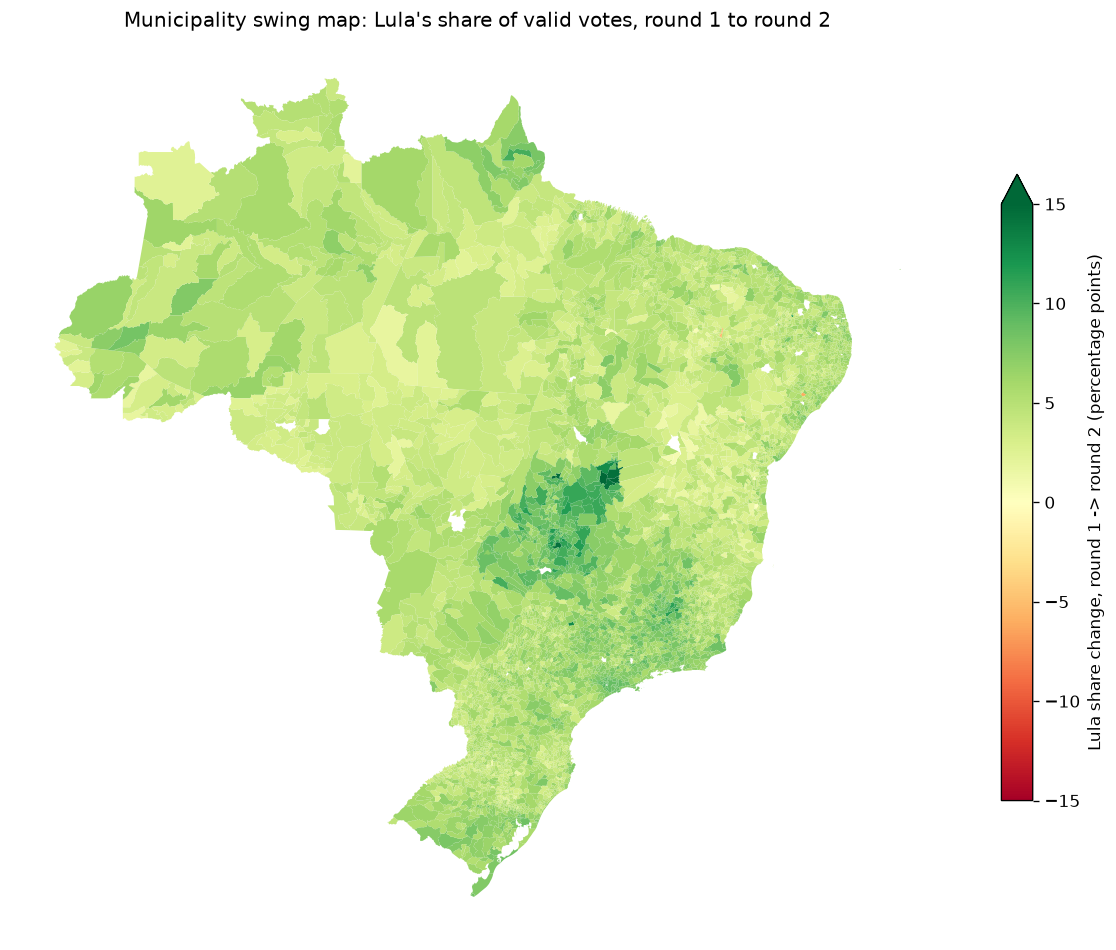

In [7]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
import geopandas as gpd
mun = pd.read_csv(PROC / "mun_swing_2026.csv", dtype={"ibge_code": str}) if "ibge_code" in pd.read_csv(PROC / "mun_2026.csv", nrows=1).columns else None
# mun_swing_2026 was saved without ibge_code (it came from mun_2026 pivots that dropped it);
# re-attach it from mun_2026.
base = pd.read_csv(PROC / "mun_2026.csv", dtype={"CD_MUNICIPIO": str, "ibge_code": str})
ibge_map = base[base["NR_TURNO"] == 1].set_index(["SG_UF", "CD_MUNICIPIO"])["ibge_code"].to_dict()
sw = pd.read_csv(PROC / "mun_swing_2026.csv", dtype={"CD_MUNICIPIO": str})
sw["ibge_code"] = [ibge_map.get((r["SG_UF"], r["CD_MUNICIPIO"])) for _, r in sw.iterrows()]
sw = sw[sw["ibge_code"].notna()].copy()
geo = gpd.read_file(ROOT / "data" / "raw" / "br_municipalities_geojson.json")
geo["ibge_code"] = geo["id"].astype(str)
merged = geo.merge(sw, on="ibge_code", how="inner")
print(f"Mapped municipalities: {len(merged):,} of {len(sw):,} swing rows with an IBGE code")
fig, ax = plt.subplots(figsize=(10, 9))
merged.plot(column="swing_pp", cmap="RdYlGn", vmin=-15, vmax=15, linewidth=0, ax=ax, legend=True,
            legend_kwds={"label": "Lula share change, round 1 -> round 2 (percentage points)", "shrink": 0.6})
ax.set_title("Municipality swing map: Lula's share of valid votes, round 1 to round 2")
ax.set_axis_off()
plt.tight_layout(); plt.savefig(CHARTS / "03_swing_map.png"); plt.show()

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


Mapped municipalities for abstention map: 5,537


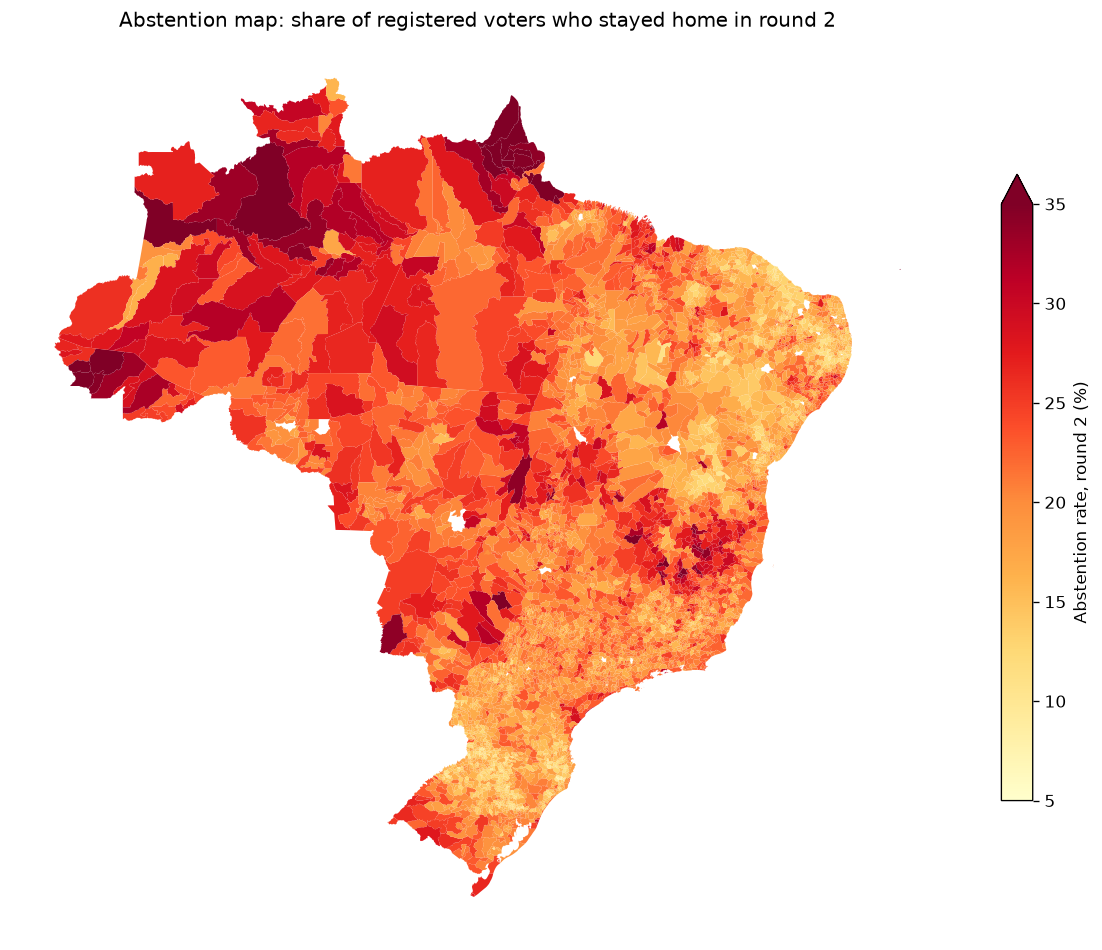

In [8]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
import geopandas as gpd
base = pd.read_csv(PROC / "mun_2026.csv", dtype={"CD_MUNICIPIO": str, "ibge_code": str})
r2 = base[(base["NR_TURNO"] == 2) & (base["SG_UF"] != "ZZ")][["SG_UF", "CD_MUNICIPIO", "ibge_code", "abstention_rate"]].copy()
r2["abstention_pct"] = r2["abstention_rate"] * 100
geo = gpd.read_file(ROOT / "data" / "raw" / "br_municipalities_geojson.json")
geo["ibge_code"] = geo["id"].astype(str)
merged = geo.merge(r2, on="ibge_code", how="inner")
print(f"Mapped municipalities for abstention map: {len(merged):,}")
fig, ax = plt.subplots(figsize=(10, 9))
merged.plot(column="abstention_pct", cmap="YlOrRd", vmin=5, vmax=35, linewidth=0, ax=ax, legend=True,
            legend_kwds={"label": "Abstention rate, round 2 (%)", "shrink": 0.6})
ax.set_title("Abstention map: share of registered voters who stayed home in round 2")
ax.set_axis_off()
plt.tight_layout(); plt.savefig(CHARTS / "03_abstention_map.png"); plt.show()

**Takeaway.** Lula's gain is fully covered, in aggregate, by the eliminated pool plus the valid-vote increase — and it *cannot* be covered by the eliminated pool alone, so turnout and blank/null/switching voters necessarily contributed at least ~1.06 million votes. The gain was also broad across municipalities, not confined to a few places. That is the arithmetic foundation. Chapter 4 puts 2026 in historical context, and Chapter 5 asks what all of this does — and does not — prove about the fraud claim.